In [1]:
PATH = "Assignment2 Data/"

In [2]:
!pip install scikit-image

Defaulting to user installation because normal site-packages is not writeable


## 1. Image Classification using HoG

In [3]:
TRAIN_DIR = PATH+"Q1/training"
TEST_DIR = PATH+"Q1/test"

In [4]:
from skimage.io import imread
from skimage.transform import resize
from skimage.feature import hog
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import cv2
import os 
import numpy as np

### 1.1 Build a classifier with training images

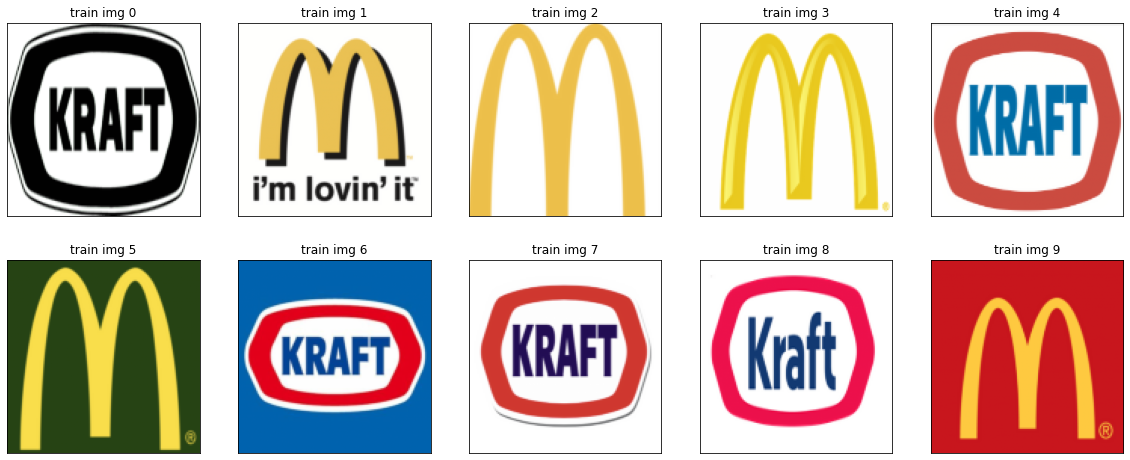

In [5]:
# 1. Resize the training images to 128 x 128. 
# read, resize, and show training set images 

IMG_SIZE = (128, 128) 
TRAIN_IMAGES = [] 
TEST_IMAGES = []
fig, ax = plt.subplots(2, 5, figsize=(20, 8))


# read images in the train and test directory 
counter = 0
for image_f in os.listdir(TRAIN_DIR):
    img = imread(os.path.join(TRAIN_DIR, image_f)) # resize train images
    img = resize(img, IMG_SIZE)
    TRAIN_IMAGES.append(img)
    ax[counter//5][counter%5].imshow(img)
    ax[counter//5][counter%5].title.set_text(f"train img {counter}")
    ax[counter//5][counter%5].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1

/tmp/ipykernel_2295302/955082359.py:8: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  hog_features = np.asarray([hog(img, orientations=NUM_ORIENTATION_BINS, pixels_per_cell=PIXELS_CELL,cells_per_block=CELLS_BLOCK, visualize=True, channel_axis=-1) for img in TRAIN_IMAGES])


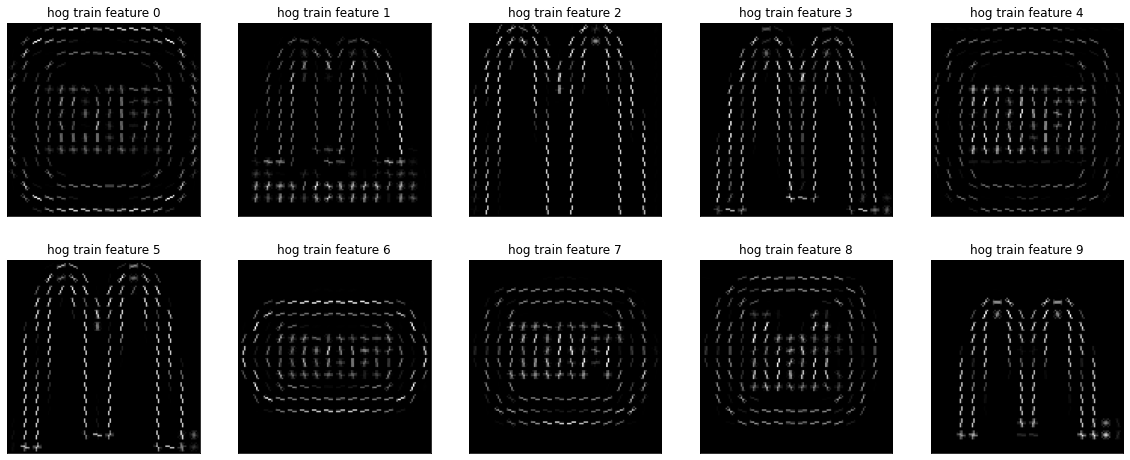

In [6]:
# constants 
PIXELS_CELL = (8, 8)
CELLS_BLOCK = (4, 4)
NUM_ORIENTATION_BINS = 8

# 2. Compute HoG features of size (32, 32, 8) for all training images.
# 3. Apply blocknorm in 4x4 cell neighborhoods.
hog_features = np.asarray([hog(img, orientations=NUM_ORIENTATION_BINS, pixels_per_cell=PIXELS_CELL,cells_per_block=CELLS_BLOCK, visualize=True, channel_axis=-1) for img in TRAIN_IMAGES])



counter = 0
fig, ax = plt.subplots(2, 5, figsize=(20, 8))
for features in hog_features:
    ax[counter//5][counter%5].imshow(features[1], cmap="gray")
    ax[counter//5][counter%5].title.set_text(f"hog train feature {counter}")
    ax[counter//5][counter%5].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1
    

features = np.array([features[0] for features in hog_features])

In [7]:
# manually label train images 
targets = ["Kraft", "McDonald’s", "McDonald’s", "McDonald’s", "Kraft", "McDonald’s", "Kraft", "Kraft", "Kraft", "McDonald’s"]

# 4. Fit a nearest neighbor classifier with three neighbors. Use KNeighborsClassifier from sklearn library.
N_NEIGHBORS = 3
clf = KNeighborsClassifier(n_neighbors = N_NEIGHBORS)
clf.fit(features, targets)

KNeighborsClassifier(n_neighbors=3)

### 1.2 Classify test images

/tmp/ipykernel_2295302/798959587.py:15: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  hog_test_features = np.asarray([hog(img, orientations=NUM_ORIENTATION_BINS, pixels_per_cell=PIXELS_CELL,cells_per_block=CELLS_BLOCK, visualize=True, channel_axis=-1) for img in TEST_IMAGES])


Predicted Label: ['Kraft' 'Kraft' 'Kraft' 'McDonald’s']


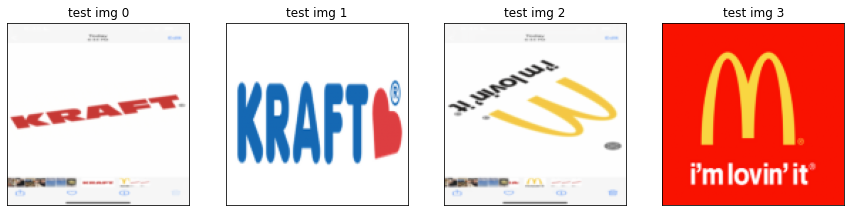

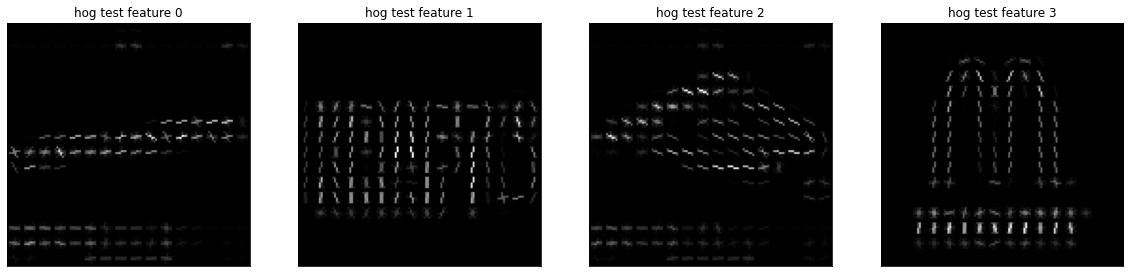

In [8]:
#1. Compute HoG features for all test images.

fig, ax = plt.subplots(1, 4, figsize=(15, 5))
counter = 0
for image_f in os.listdir(TEST_DIR):
    img = imread(os.path.join(TEST_DIR, image_f)) # resize train images
    img = resize(img, IMG_SIZE)
    TEST_IMAGES.append(img)
    ax[counter%4].imshow(img)
    ax[counter%4].title.set_text(f"test img {counter}")
    ax[counter%4].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1
    
#2. Display the HoG features for all test images.
hog_test_features = np.asarray([hog(img, orientations=NUM_ORIENTATION_BINS, pixels_per_cell=PIXELS_CELL,cells_per_block=CELLS_BLOCK, visualize=True, channel_axis=-1) for img in TEST_IMAGES])
counter = 0
fig, ax = plt.subplots(1, 4, figsize=(20, 8))
for features in hog_test_features:
    ax[counter%4].imshow(features[1], cmap="gray")
    ax[counter%4].title.set_text(f"hog test feature {counter}")
    ax[counter%4].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1
    
features_test = np.array([features[0] for features in hog_test_features])

# 3. Classify the test images using the classifier you built above.
# predict test set labels 
print("Predicted Label:", clf.predict(features_test))

4. Does the classifier work on all test images? Discuss which properties of HoG features help
to classify the images. Which computer vision methods will you use for classifying logos
under rotation.

No as we can see from above the classifier works on most images (3 out of 4 test set images). It classifies the third image (McDonald’s) incorrectly as Kraft. Looking more closely, we see that the misclassified image is highly rotated. While HOG is generally robust to changes in scale and translation, it can underperform when the object is rotated. SIFT (Scale-Invariant Feature Transform), SURF (Speeded Up Robust Features), ORB (Oriented FAST and Rotated BRIEF) are methods that would me rotation invariant or less influenced by rotation.

## 2. Image stitching 

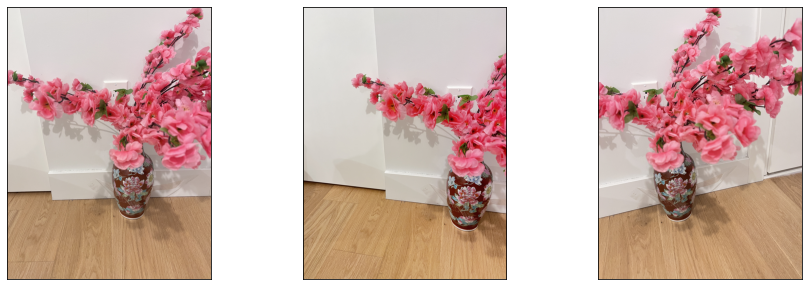

In [5]:
img1 = cv2.imread(PATH + "Q2/image2.jpeg")  # in BGR
img2 = cv2.imread(PATH + "Q2/image1.jpeg")  # in BGR
img3 = cv2.imread(PATH + "Q2/image3.jpeg")  # in BGR

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
img3 = cv2.cvtColor(img3, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img1)
ax[1].imshow(img2)
ax[2].imshow(img3)
for axs in ax: 
    axs.tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)

In [6]:
#1. Compute the SIFT keypoints and corresponding descriptors for image1 and image 2.

keypoints, descriptors = [], []

# for img1 
# Create a SIFT object
sift = cv2.SIFT_create()
ks, ds = sift.detectAndCompute(img1, None) # Compute the keypoints/descriptors
keypoints.append(ks)
descriptors.append(ds)

# for img1 
# Create a SIFT object
# sift = cv2.SIFT_create()
ks, ds = sift.detectAndCompute(img2, None) # Compute the keypoints/descriptors
keypoints.append(ks)
descriptors.append(ds)

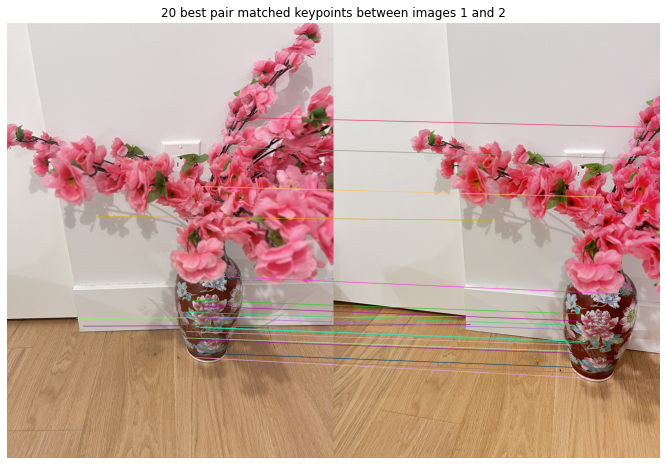

In [7]:
#2. Find matching keypoints in image 1 and image 2, and display the 20 best pairs.

bf = cv2.BFMatcher()  # cv2.NORM_HAMMING, crossCheck=True)

# Match descriptors.
matches = bf.match(descriptors[0], descriptors[1])  

# Sort them in the order of their distance.
matches_s = sorted(matches, key=lambda x: x.distance)

# Draw first 20 matches.
matched_img = cv2.drawMatches(
    img1,
    keypoints[0],
    img2,
    keypoints[1],
    matches_s[:20],
    None,
    flags=2,
    matchesThickness=3
)

plt.figure(figsize=(16, 8))
plt.imshow(matched_img)
plt.axis('off')
plt.title(
    f"20 best pair matched keypoints between images 1 and 2"
)
plt.show()

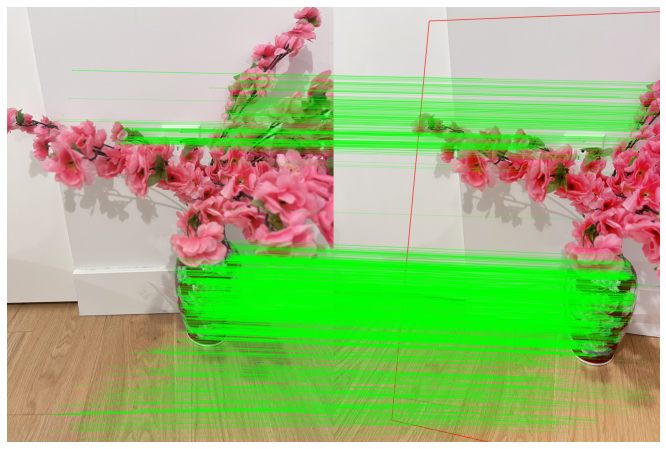

In [8]:
src_pts = np.float32([ keypoints[0][m.queryIdx].pt for m in matches ]).reshape(-1,1,2)
dst_pts = np.float32([ keypoints[1][m.trainIdx].pt for m in matches ]).reshape(-1,1,2)
M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC,5.0)
matchesMask = mask.ravel().tolist()

h,w, _ = img1.shape
pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1,1,2)
dst = cv2.perspectiveTransform(pts,M)
img2_new = cv2.polylines(img2,[np.int32(dst)],True,255,3, cv2.LINE_AA)


draw_params = dict(matchColor = (0,255,0), # draw matches in green color
                   singlePointColor = None,
                   matchesMask = matchesMask, # draw only inliers
                   flags = 2)
img30 = cv2.drawMatches(img1,keypoints[0],img2_new,keypoints[1],matches,None,**draw_params)
plt.figure(figsize=(16, 8))
plt.imshow(img30)
plt.axis('off')
plt.show()

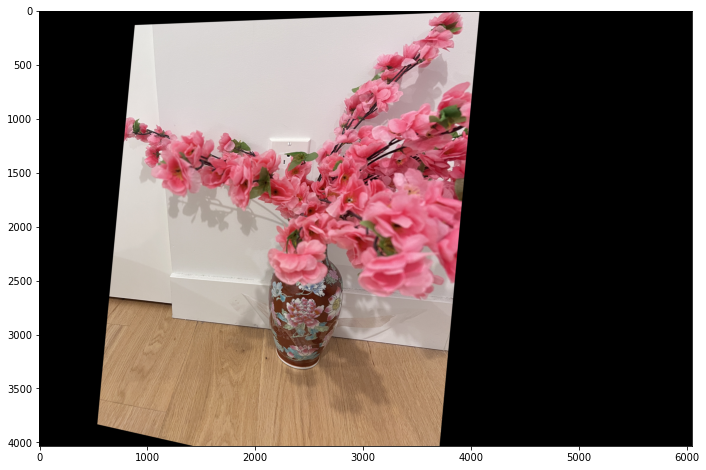

In [9]:
plt.figure(figsize=(16, 8))
warped_img1 = cv2.warpPerspective(img1, M, (img1.shape[1] + img2.shape[1], img2.shape[0]))
plt.imshow(warped_img1)

In [20]:
def pyr_blending(): 
    A = warped_img1
    B = img2
    # pyramid blending
    # generate Gaussian pyramid for A
    G = A.copy()
    gpA = [G]
    for i in range(6):
        G = cv.pyrDown(G)
        gpA.append(G)
    # generate Gaussian pyramid for B
    G = B.copy()
    gpB = [G]
    for i in range(6):
        G = cv.pyrDown(G)
        gpB.append(G)
    # generate Laplacian Pyramid for A
    lpA = [gpA[5]]
    for i in range(5,0,-1):
        GE = cv.pyrUp(gpA[i])
        L = cv.subtract(gpA[i-1],GE)
        lpA.append(L)
    # generate Laplacian Pyramid for B
    lpB = [gpB[5]]
    for i in range(5,0,-1):
        GE = cv.pyrUp(gpB[i])
        L = cv.subtract(gpB[i-1],GE)
        lpB.append(L)
    # Now add left and right halves of images in each level
    LS = []
    for la,lb in zip(lpA,lpB):
        rows,cols,dpt = la.shape
        ls = np.hstack((la[:,0:cols//2], lb[:,cols//2:]))
        LS.append(ls)
    # now reconstruct
    ls_ = LS[0]
    for i in range(1,6):
        ls_ = cv.pyrUp(ls_)
        ls_ = cv.add(ls_, LS[i])
    res = ls_
    return res

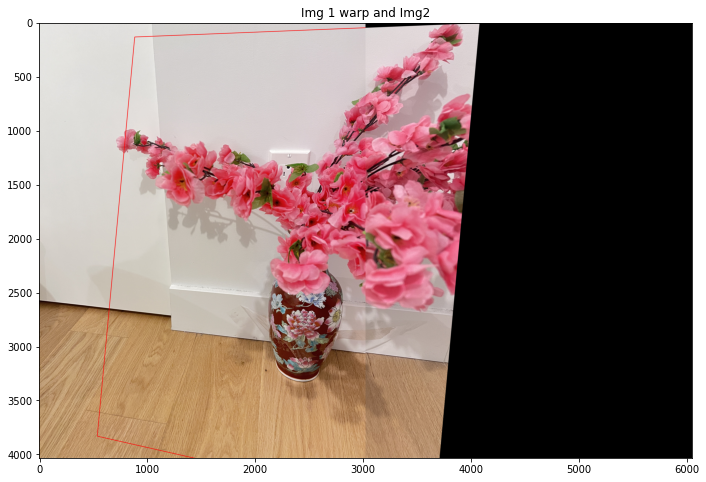

In [10]:
plt.figure(figsize=(16, 8))
warped_img1[0:img2.shape[0], 0:img2.shape[1]] = img2
plt.title("Img 1 warp and Img2")
plt.imshow(warped_img1)
img12 = warped_img1

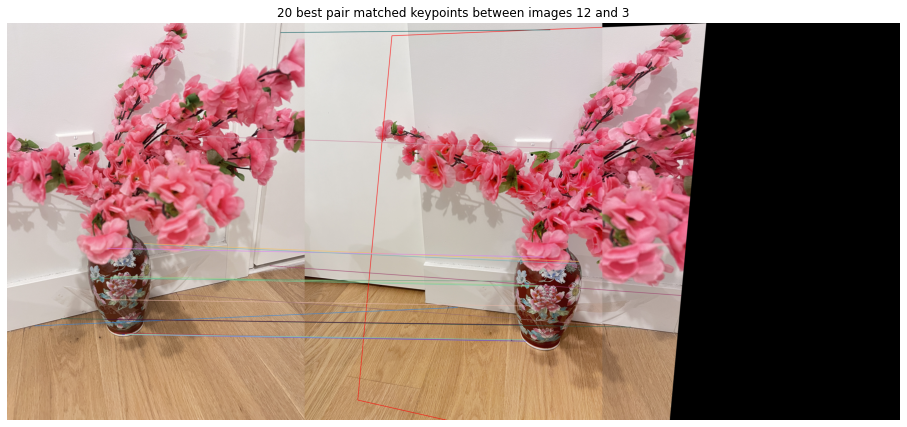

In [17]:
# 5. Compute the SIFT keypoints and corresponding descriptors for images 12 and 3.
# 6. Find matching keypoints in image 12 and image 3, and display the 20 best pairs.

img3 = cv2.imread(PATH + "Q2/image3.jpeg")  # in BGR
img3 = cv2.cvtColor(img3, cv2.COLOR_BGR2RGB)


ks, ds = sift.detectAndCompute(img3, None) # Compute the keypoints/descriptors
keypoints.append(ks)
descriptors.append(ds)

ks, ds = sift.detectAndCompute(img12, None) # Compute the keypoints/descriptors
keypoints.append(ks)
descriptors.append(ds)

bf = cv2.BFMatcher()  # cv2.NORM_HAMMING, crossCheck=True)

# Match descriptors.
matches = bf.match(descriptors[2], descriptors[3])  

# Sort them in the order of their distance.
matches_s = sorted(matches, key=lambda x: x.distance)

# Draw first 20 matches.
matched_img = cv2.drawMatches(
    img3,
    keypoints[2],
    img12,
    keypoints[3],
    matches_s[:20],
    None,
    flags=2,
    matchesThickness=3
)

plt.figure(figsize=(16, 8))
plt.imshow(matched_img)
plt.axis('off')
plt.title(
    f"20 best pair matched keypoints between images 12 and 3"
)
plt.show()

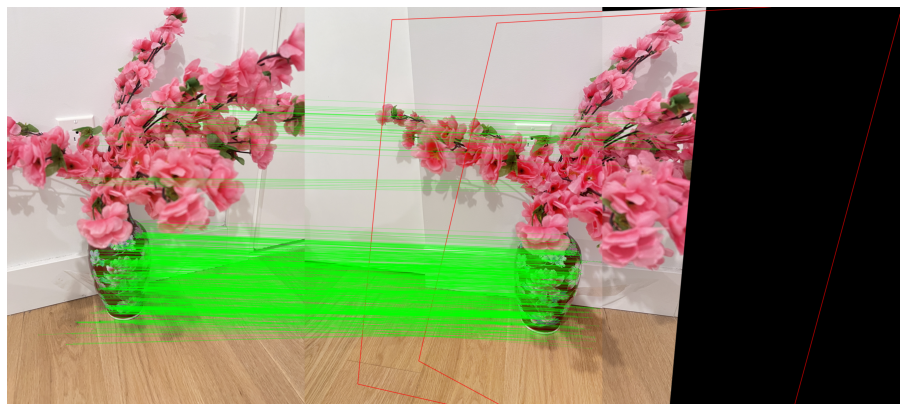

In [18]:
src_pts = np.float32([ keypoints[2][m.queryIdx].pt for m in matches ]).reshape(-1,1,2)
dst_pts = np.float32([ keypoints[3][m.trainIdx].pt for m in matches ]).reshape(-1,1,2)
M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC,5.0)
matchesMask = mask.ravel().tolist()

h,w, _ = img3.shape
pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1,1,2)
dst = cv2.perspectiveTransform(pts,M)
img12_new = cv2.polylines(img12,[np.int32(dst)],True,255,3, cv2.LINE_AA)


draw_params = dict(matchColor = (0,255,0), # draw matches in green color
                   singlePointColor = None,
                   matchesMask = matchesMask, # draw only inliers
                   flags = 2)
img30 = cv2.drawMatches(img3,keypoints[2],img12_new,keypoints[3],matches,None,**draw_params)
plt.figure(figsize=(16, 8))
plt.imshow(img30)
plt.axis('off')
plt.show()

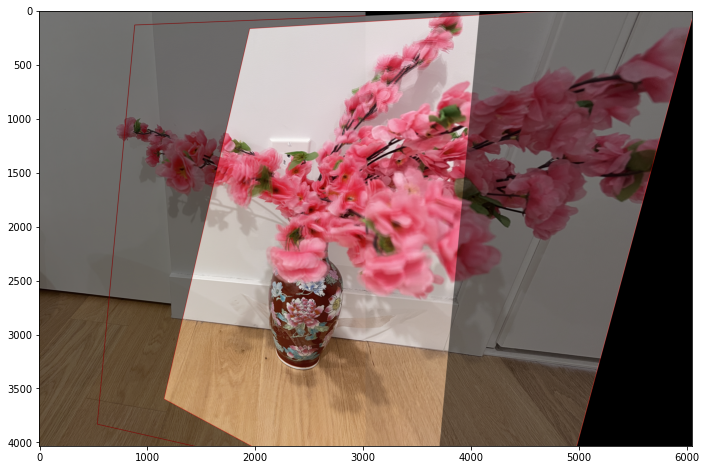

In [19]:
img2_transformed = cv2.warpPerspective(img3, M, (img12.shape[1], img12.shape[0]))
result = cv2.addWeighted(img12, 0.5, img2_transformed, 0.5, 0)
plt.figure(figsize=(16, 8))
plt.imshow(result)

9. Discuss which method you prefer for stitching - pyramid blending or linear blending, and
why?

The preferred method would depend highly on the application and requirements of the final image. However, pyramid blending produces smoother and more seamless transitions between stitched images. This results in less visible seams or artifacts. Furthermore, it can mitigate significant differences in exposure, brightness, and color between two images.
However, it has the drawback of being more computationally expensive than linear blending and can result in lower resolution images due to down-sampling at each level of the pyramid. It should also be mentioned that parameters would need to be finetuned for optimal performance. On the other hand, linear blending isn't computationally expensive but resulting image has more artifacts but does not require much tuning. 

## 3. Face detection

In [20]:
TRAIN_PATH = PATH + "Q3/faces"
training_list = os.listdir(TRAIN_PATH) 

dataset = []

for img in training_list:
    image_path = os.path.join(TRAIN_PATH, img)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    dataset.append(image)

# Convert the list of images to a numpy array
dataset = np.array(dataset)

# Print the shape of the images array
print("Dataset shape:", dataset.shape)

Dataset shape: (400, 218, 178)


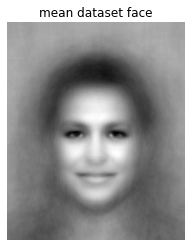

In [21]:
#1. Display the mean face of the training dataset.

mean_face = np.mean(dataset, axis=0)
plt.imshow(mean_face, cmap = 'gray')
plt.title("mean dataset face")
plt.axis(False)
plt.show()

In [22]:
print("original dataset shape:", dataset.shape)
dataset_flat = dataset.reshape(dataset.shape[0], -1)
print("flattened dataset shape:", dataset_flat.shape)

original dataset shape: (400, 218, 178)
flattened dataset shape: (400, 38804)


In [23]:
from sklearn.decomposition import PCA

pca = PCA(n_components=30)
pca.fit(dataset_flat)
data_transf = pca.transform(dataset_flat)

eigenvalues = pca.explained_variance_
eigenvectors = pca.components_

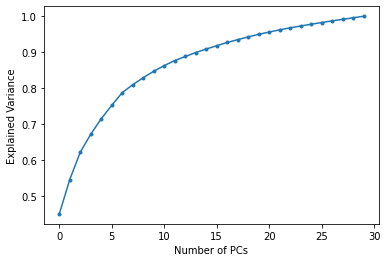

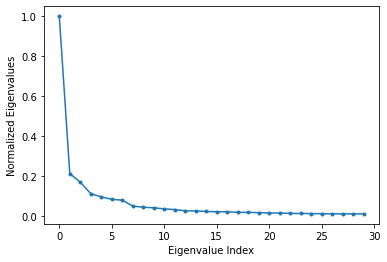

In [24]:
# Explained variance ratio
plt.figure()
plt.plot(np.cumsum(eigenvalues) / np.sum(eigenvalues),'.-')
plt.xlabel('Number of PCs')
plt.ylabel('Explained Variance')
plt.show()

# normalized eigenvalues 
norm_eigenvalues = eigenvalues / eigenvalues.max()

plt.figure()
plt.plot(norm_eigenvalues,'.-')
plt.xlabel('Eigenvalue Index')
plt.ylabel('Normalized Eigenvalues')
plt.show()

In [25]:
# Get the indices that would sort the eigenvalues in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]  

sorted_eigenvalues = eigenvalues[sorted_indices]
sorted_eigenvectors = eigenvectors[sorted_indices]

print("Sorted Eigenvalues:", sorted_eigenvalues[:4])

Sorted Eigenvalues: [72963017.78047152 15449192.36516208 12282224.90821926  8086695.43094605]


The eigenfaces faces: 


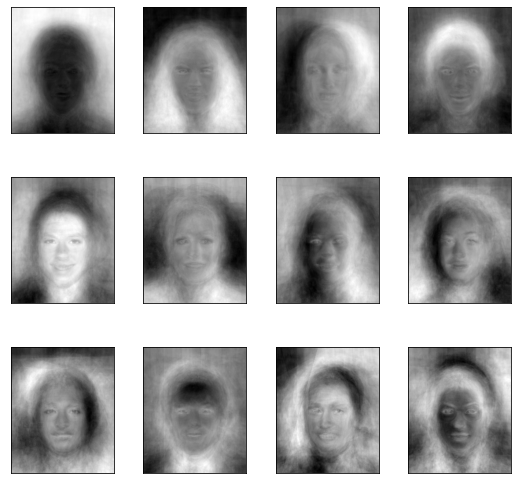

In [26]:
reshaped_eigenfaces = eigenvectors.reshape((30, 218, 178))

def plot_gallery(images, n_row=3, n_col=4):
    """Helper function to plot a gallery of portraits"""
    plt.figure(figsize=(1.8 * n_col, 2.4 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i], cmap=plt.cm.gray)
        plt.xticks(())
        plt.yticks(())

print("The eigenfaces faces: ")
plot_gallery(reshaped_eigenfaces)
plt.show()

(20, 38804)
(218, 178)


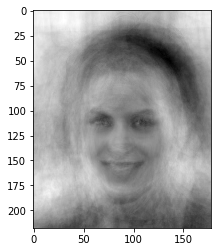

k = 20: reconstruction error = 6376.160542217956
(10, 38804)
(218, 178)


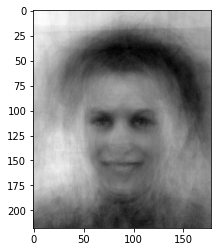

k = 10: reconstruction error = 7493.272175140994
(5, 38804)
(218, 178)


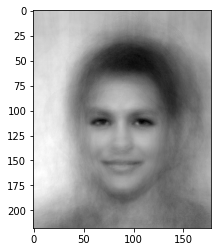

k = 5: reconstruction error = 8736.588038803808
(50, 38804)
(218, 178)


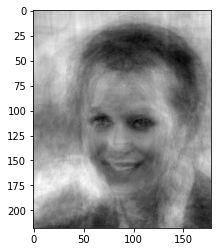

k = 50: reconstruction error = 4939.628510024936
(100, 38804)
(218, 178)


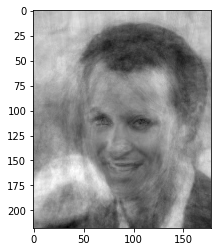

k = 100: reconstruction error = 3782.9936989111466


In [27]:
import numpy as np
from sklearn.decomposition import PCA

# Define the number of eigenvectors to use for reconstruction
k_values = [20, 10, 5, 50, 100]

# Compute the mean face vector
mean_face = np.mean(dataset_flat, axis=0)

pca = PCA(n_components=400)
pca.fit(dataset_flat)

# Loop over the different k values and compute the reconstruction error
for k in k_values:
    # Extract the first k eigenvectors
    eigenvectors = pca.components_[:k]
    print(eigenvectors.shape)

    # Project the dataset onto the first k eigenvectors
    projected = np.dot(dataset_flat - mean_face, eigenvectors.T)
    
    # Reconstruct the dataset using the first k eigenvectors
    reconstructed = np.dot(projected, eigenvectors) + mean_face
    toshow = np.resize(reconstructed[10], (218, 178))
    print(toshow.shape)
    plt.imshow(toshow, cmap="gray")
    plt.show()
    
    # Compute the reconstruction error
    error = np.mean(np.linalg.norm(dataset_flat - reconstructed, axis=1))
    
    # Print the reconstruction error for this value of k
    print("k = {}: reconstruction error = {}".format(k, error))

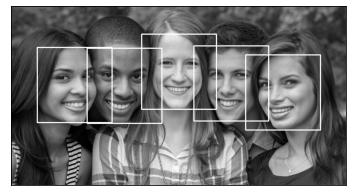

In [28]:
face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')

img = cv2.imread(PATH+"Q3/test.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

faces = face_cascade.detectMultiScale(gray, 2, 2)

for (x,y,w,h) in faces:
    gray = cv2.rectangle(gray,(x,y),(x+w,y+h),(255,0,0),2)

plt.imshow(gray, cmap="gray")
plt.xticks(())
plt.yticks(())
plt.show()

2. Describe how well the method works.

We can see from the image above that all faces were detected. So the method works quite well on this one example. However, when images are taken from the sides or different angles, we might get worse results as we trained mainly on centered face data facing forward. The more number of components we include, a better result we get at the expense of extra computation. We use 30 PCs.